In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [73]:
df= pd.read_csv('/content/diabetes.csv')

In [74]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [75]:
df.shape

(768, 9)

In [76]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [77]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [78]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [79]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [80]:
numeric_columns= df.select_dtypes(include=['int64','float64']).columns.drop('Outcome')

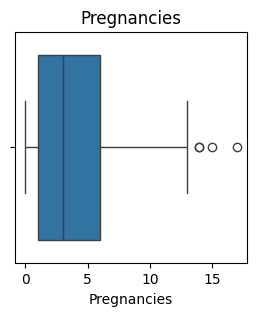

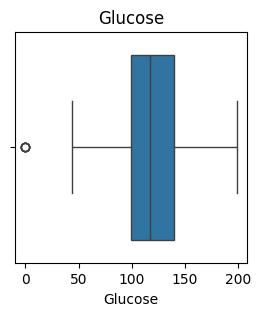

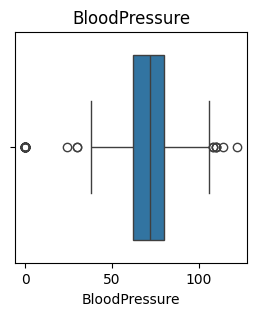

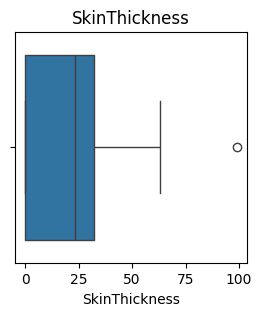

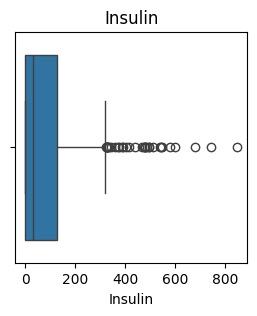

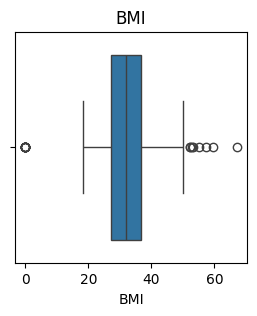

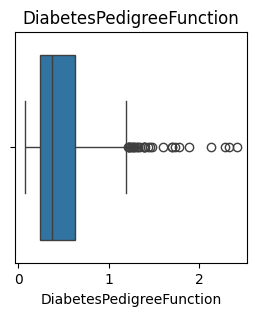

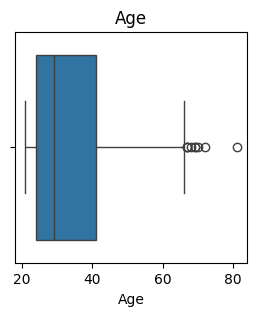

In [81]:
for col in numeric_columns:
  plt.figure(figsize=(3,3))
  sns.boxplot(x=df[col])
  plt.title(col)
  plt.show()

In [82]:
for col in numeric_columns:
  Q1= df[col].quantile(0.25)
  Q3= df[col].quantile(0.75)
  IQR=Q3-Q1
  LL= Q1- 1.5*IQR
  UL= Q3+ 1.5*IQR

  df[col]= df[col].clip(LL,UL)

In [83]:
x= df.drop('Outcome', axis=1)
y= df['Outcome']

In [84]:
from numpy.random.mtrand import RandomState
x_train,x_test,y_train,y_test= train_test_split(x,y,test_size=0.2,random_state=42)

In [85]:
x_train.shape

(614, 8)

In [86]:
x_test.shape

(154, 8)

In [87]:
y_train.shape

(614,)

In [88]:
from sklearn.linear_model import LogisticRegression
LR=LogisticRegression(max_iter=1000)
LR.fit(x_train,y_train)
y_pred=LR.predict(x_test)

In [89]:
from sklearn.metrics import accuracy_score, precision_score, confusion_matrix, classification_report

In [90]:
print(accuracy_score(y_test,y_pred))

0.7532467532467533


In [109]:
lr_accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:", lr_accuracy)

Logistic Regression Accuracy: 0.7532467532467533


In [91]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.81      0.81      0.81        99
           1       0.65      0.65      0.65        55

    accuracy                           0.75       154
   macro avg       0.73      0.73      0.73       154
weighted avg       0.75      0.75      0.75       154



In [92]:
print(confusion_matrix(y_test,y_pred))

[[80 19]
 [19 36]]


5 fold cross validation

In [93]:
from sklearn.model_selection import cross_val_score

In [94]:
cv_scores= cross_val_score(LR,x_train,y_train,cv=5,scoring='accuracy')
cv_accuracy = cv_scores.mean()
print("CV_Scores:",cv_scores)
print("Mean CV Accuracy:", cv_scores.mean())

CV_Scores: [0.76422764 0.81300813 0.73170732 0.75609756 0.77868852]
Mean CV Accuracy: 0.7687458349993335


GridSearcch CV

In [95]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
model_lr= LogisticRegression(max_iter=1000)

In [96]:
classifier= GridSearchCV(model_lr,
            {
                'C': [0.01,0.1,1,10,100]
            },
            cv=5,
            return_train_score=False)

classifier.fit(x_train,y_train)

GridSearchCV(cv=5, estimator=LogisticRegression(max_iter=1000),
             param_grid={'C': [0.01, 0.1, 1, 10, 100]})

In [97]:
classifier.best_params_

{'C': 1}

In [98]:
classifier.best_score_

np.float64(0.7687458349993335)

In [99]:
results_grid=pd.DataFrame(classifier.cv_results_); results_grid

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_C,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.096394,0.035027,0.006140,0.002439,0.01,{'C': 0.01},0.739837,0.821138,0.756098,0.739837,0.762295,0.763841,0.029992,5
1,0.074755,0.015583,0.005032,0.002022,0.10,{'C': 0.1},0.747967,0.813008,0.747967,0.747967,0.770492,0.765480,0.025314,4
2,0.089382,0.032944,0.004757,0.002021,1.00,{'C': 1},0.764228,0.813008,0.731707,0.756098,0.778689,0.768746,0.026871,1
3,0.069130,0.005548,0.004137,0.000904,10.00,{'C': 10},0.764228,0.813008,0.715447,0.747967,0.795082,0.767146,0.034447,2
4,0.060694,0.006027,0.004361,0.001505,100.00,{'C': 100},0.764228,0.813008,0.715447,0.747967,0.795082,0.767146,0.034447,2


In [100]:
y_pred_grid = classifier.predict(x_test)

In [101]:
from sklearn.metrics import accuracy_score
grid_accuracy = accuracy_score(y_test,y_pred_grid)
print("GridSearch Accuracy:",grid_accuracy)

GridSearch Accuracy: 0.7532467532467533


Randomized Search CV

In [102]:
from sklearn.model_selection import RandomizedSearchCV
classifier_r= RandomizedSearchCV(model_lr,
            {
                'C': [0.01,0.1,1,10,100]
            },
            n_iter=5,cv=5,
            return_train_score=False, random_state=42)

classifier_r.fit(x_train,y_train)

RandomizedSearchCV(cv=5, estimator=LogisticRegression(max_iter=1000), n_iter=5,
                   param_distributions={'C': [0.01, 0.1, 1, 10, 100]},
                   random_state=42)

In [103]:
classifier_r.best_params_

{'C': 1}

In [104]:
classifier_r.best_score_

np.float64(0.7687458349993335)

In [105]:
results_random = pd.DataFrame(classifier_r.cv_results_); results_random

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_C,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.073244,0.031958,0.004205,0.001383,0.01,{'C': 0.01},0.739837,0.821138,0.756098,0.739837,0.762295,0.763841,0.029992,5
1,0.121563,0.090655,0.004662,0.002329,0.10,{'C': 0.1},0.747967,0.813008,0.747967,0.747967,0.770492,0.765480,0.025314,4
2,0.078055,0.010307,0.003783,0.000648,1.00,{'C': 1},0.764228,0.813008,0.731707,0.756098,0.778689,0.768746,0.026871,1
3,0.070198,0.010906,0.005831,0.002151,10.00,{'C': 10},0.764228,0.813008,0.715447,0.747967,0.795082,0.767146,0.034447,2
4,0.076869,0.015076,0.006310,0.001055,100.00,{'C': 100},0.764228,0.813008,0.715447,0.747967,0.795082,0.767146,0.034447,2


In [106]:
y_pred_random = classifier_r.predict(x_test)
random_accuracy=accuracy_score(y_test,y_pred_random)
print("RandomizedSearch Accuracy:",random_accuracy)

RandomizedSearch Accuracy: 0.7532467532467533


Ensemble Model

In [107]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, confusion_matrix, classification_report
model_rf = RandomForestClassifier(n_estimators=100,random_state=42)
model_rf.fit(x_train,y_train)
y_pred_rf = model_rf.predict(x_test)
rf_accuracy=accuracy_score(y_test,y_pred_rf)
print("Random Forest Accuracy:", rf_accuracy)
print(confusion_matrix(y_test,y_pred_rf))
print(classification_report(y_test,y_pred_rf))

Random Forest Accuracy: 0.7207792207792207
[[77 22]
 [21 34]]
              precision    recall  f1-score   support

           0       0.79      0.78      0.78        99
           1       0.61      0.62      0.61        55

    accuracy                           0.72       154
   macro avg       0.70      0.70      0.70       154
weighted avg       0.72      0.72      0.72       154



Final Comparision Table

In [116]:
import pandas as pd

lr_accuracy = accuracy_score(y_test, y_pred)

final_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'GridSearchCV Logistic Regression',
        'RandomizedSearchCV Logistic Regression',
        'Random Forest'
    ],

    'Test Accuracy': [
        lr_accuracy,
        grid_accuracy,
        random_accuracy,
        rf_accuracy
    ],

})

final_results

,Model,Test Accuracy
0,Logistic Regression,0.753247
1,GridSearchCV Logistic Regression,0.753247
2,RandomizedSearchCV Logistic Regression,0.753247
3,Random Forest,0.720779
